In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    roc_curve, classification_report)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SVMSMOTE
from xgboost import XGBClassifier
import joblib, warnings, time
SEED=42
sns.set_theme(style="whitegrid")
print("Environnement prêt")

Environnement prêt


In [2]:
import sklearn, imblearn, xgboost
print('Versions : pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| imbalanced-learn', imblearn.__version__, '| xgboost', xgboost.__version__)

Versions : pandas 3.1.0 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | xgboost 3.4.1


## 1 — Chargement des données
Source publique : [UCI AI4I 2020 Predictive Maintenance](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset). Placer `ai4i2020.csv` à côté du notebook, ou autoriser le téléchargement automatique.

In [3]:
path=Path('ai4i2020.csv')
if not path.exists():
    import urllib.request
    url='https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip'
    import zipfile, io
    with urllib.request.urlopen(url,timeout=30) as response:
        archive=zipfile.ZipFile(io.BytesIO(response.read()))
    csv_name=next((name for name in archive.namelist() if name.lower().endswith('.csv')),None)
    if csv_name is None: raise FileNotFoundError('CSV absent de l’archive UCI')
    path.write_bytes(archive.read(csv_name))
df=pd.read_csv(path)
print('Dimensions :',df.shape)
display(df.head())
print('Colonnes :',df.columns.tolist())

Dimensions : (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Colonnes : ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


## 2 — Qualité des données et EDA

In [4]:
display(df.describe(include='all').T)
display(pd.DataFrame({'Valeurs manquantes':df.isna().sum(),'Types':df.dtypes.astype(str)}))
print('Doublons complets :',df.duplicated().sum())
print('Répartition cible :');display(df['Machine failure'].value_counts().rename_axis('Classe').to_frame('Effectif'))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


,Valeurs manquantes,Types
UDI,0,int64
Product ID,0,str
Type,0,str
Air temperature [K],0,float64
Process temperature [K],0,float64
Rotational speed [rpm],0,int64
Torque [Nm],0,float64
Tool wear [min],0,int64
Machine failure,0,int64
TWF,0,int64


Doublons complets : 0
Répartition cible :


,Effectif
Classe,
0,9661
1,339


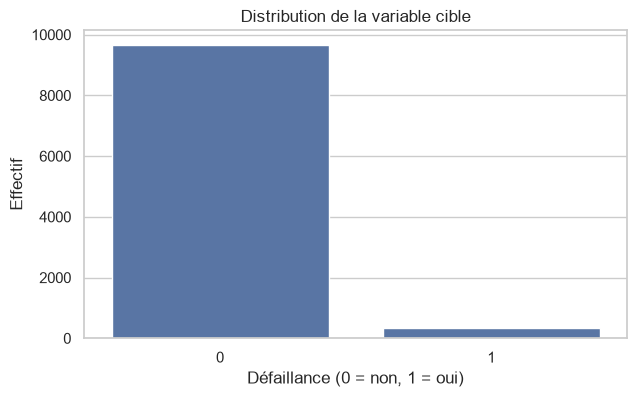

Prévalence des défaillances : 3.39%


In [5]:
fig,ax=plt.subplots(figsize=(7,4))
sns.countplot(data=df,x='Machine failure',ax=ax)
ax.set(title='Distribution de la variable cible',xlabel='Défaillance (0 = non, 1 = oui)',ylabel='Effectif');plt.show()
print('Prévalence des défaillances : {:.2%}'.format(df['Machine failure'].mean()))

,Occurrences
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19


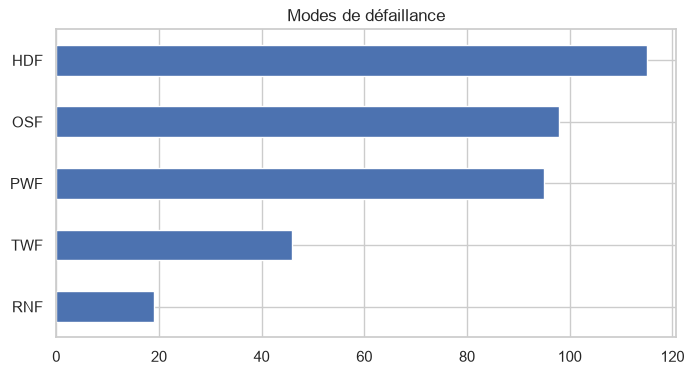

Incohérences cible vs au moins un mode : 27
La cible originale est conservée : les modes de panne ne seront pas utilisés comme prédicteurs.


In [6]:
modes=['TWF','HDF','PWF','OSF','RNF']
display(df[modes].sum().sort_values(ascending=False).to_frame('Occurrences'))
df[modes].sum().sort_values().plot.barh(figsize=(8,4),title='Modes de défaillance');plt.show()
print('Incohérences cible vs au moins un mode :',int((df['Machine failure'] != df[modes].max(axis=1)).sum()))
print('La cible originale est conservée : les modes de panne ne seront pas utilisés comme prédicteurs.')

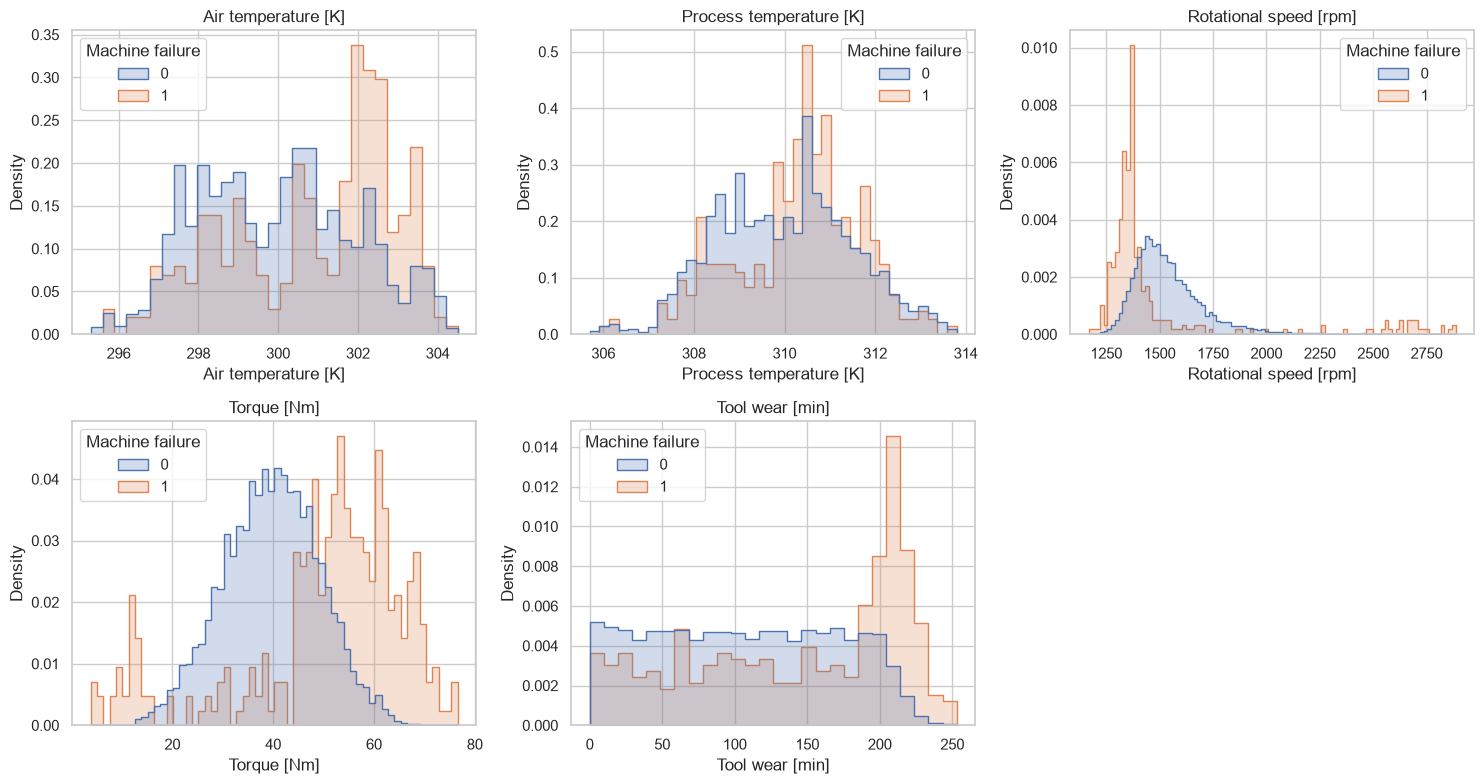

In [7]:
numeric=['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']
fig,axs=plt.subplots(2,3,figsize=(15,8));axs=axs.ravel()
for ax,col in zip(axs,numeric):
    sns.histplot(data=df,x=col,hue='Machine failure',element='step',stat='density',common_norm=False,ax=ax)
    ax.set_title(col)
for ax in axs[len(numeric):]:ax.axis('off')
plt.tight_layout();plt.show()

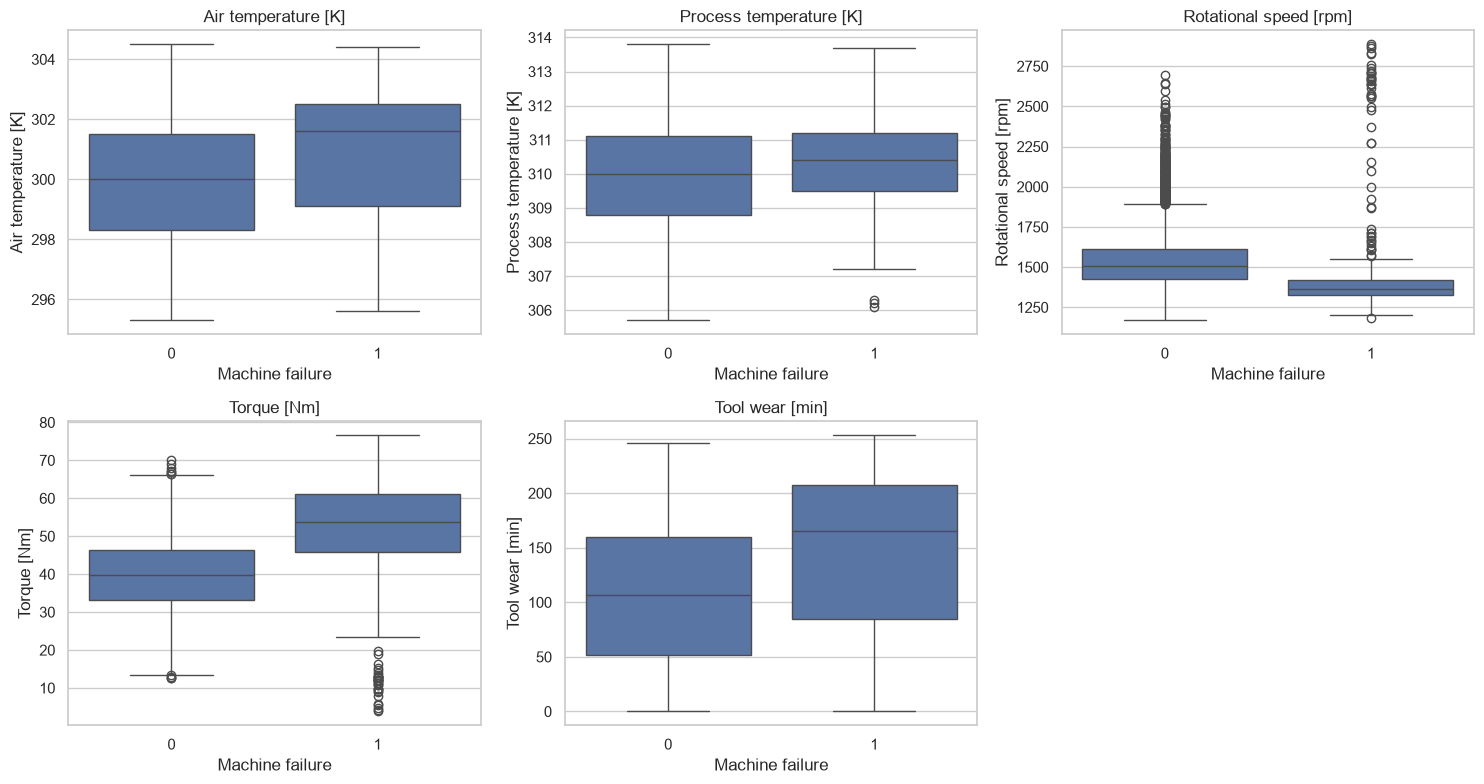

In [8]:
fig,axs=plt.subplots(2,3,figsize=(15,8));axs=axs.ravel()
for ax,col in zip(axs,numeric):
    sns.boxplot(data=df,x='Machine failure',y=col,ax=ax)
    ax.set_title(col)
for ax in axs[len(numeric):]:ax.axis('off')
plt.tight_layout();plt.show()

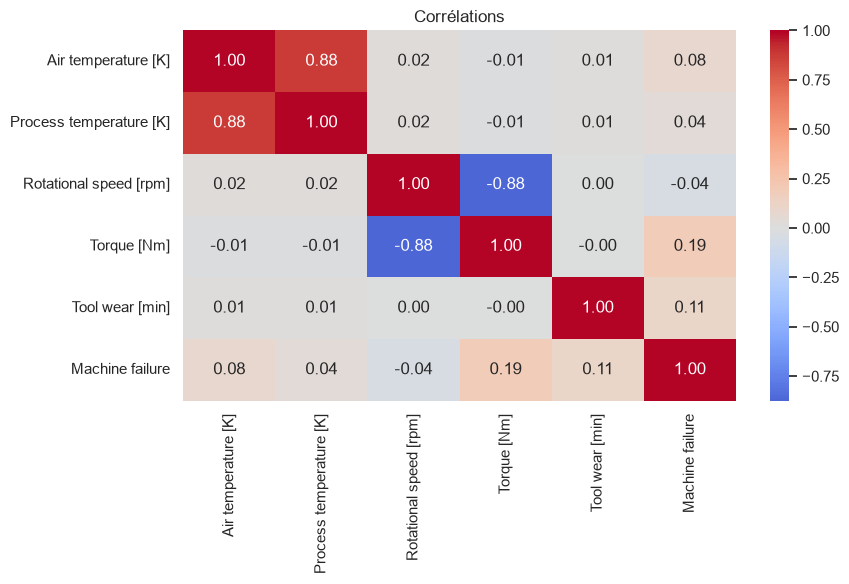

In [9]:
plt.figure(figsize=(9,6));sns.heatmap(df[numeric+['Machine failure']].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0);plt.title('Corrélations');plt.tight_layout();plt.show()

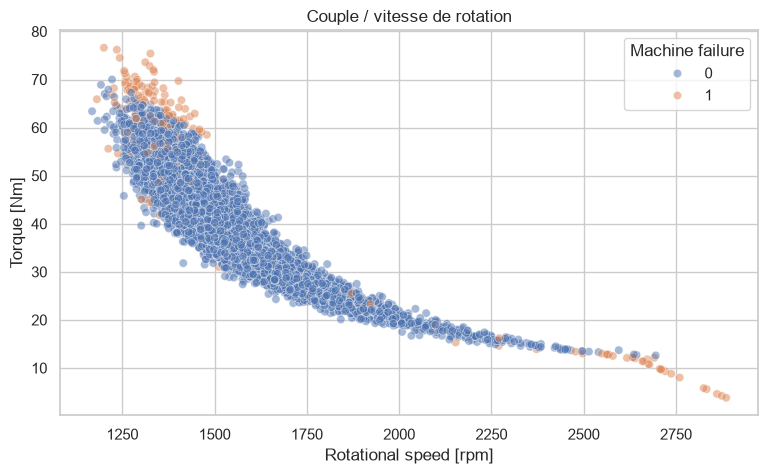

,Taux de défaillance,count
Type,,
H,0.020937,1003
L,0.039167,6000
M,0.027694,2997


In [10]:
fig,ax=plt.subplots(figsize=(9,5))
sns.scatterplot(data=df,x='Rotational speed [rpm]',y='Torque [Nm]',hue='Machine failure',alpha=.5,ax=ax)
ax.set_title('Couple / vitesse de rotation');plt.show()
display(df.groupby('Type')['Machine failure'].agg(['mean','count']).rename(columns={'mean':'Taux de défaillance'}))

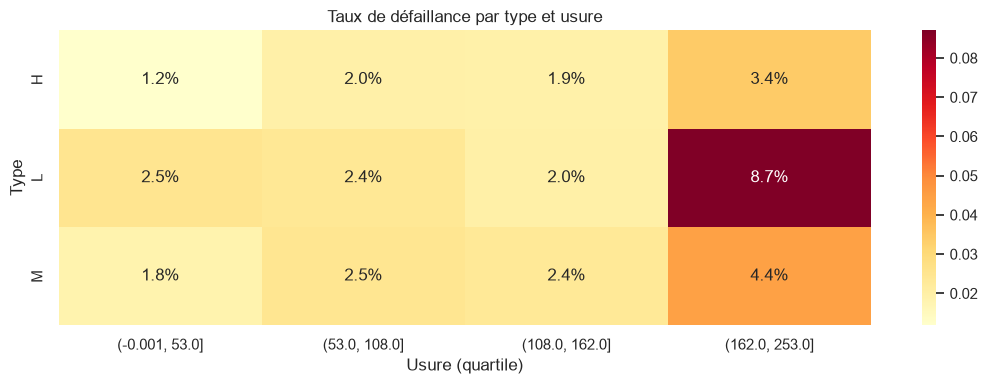

In [11]:
tmp=df[['Type','Tool wear [min]','Machine failure']].copy()
tmp['Usure (quartile)']=pd.qcut(tmp['Tool wear [min]'],4,duplicates='drop')
pivot=tmp.pivot_table(index='Type',columns='Usure (quartile)',values='Machine failure',aggfunc='mean',observed=True)
plt.figure(figsize=(11,4));sns.heatmap(pivot,annot=True,fmt='.1%',cmap='YlOrRd');plt.title('Taux de défaillance par type et usure');plt.tight_layout();plt.show()

## 3 — Variables et protocole sans fuite de données
- Cible : `Machine failure` originale.
- Exclure `UDI`, `Product ID` et les cinq modes TWF/HDF/PWF/OSF/RNF : ces derniers peuvent révéler directement la panne.
- Ajouter des variables physiques calculables au moment de la prédiction.
- Réserver **20 % des données pour le test final** avant tout apprentissage.


**Important :** `Machine failure` est conservée telle que fournie par UCI ; les colonnes TWF/HDF/PWF/OSF/RNF sont exclues des prédicteurs, car elles renseignent directement sur les modes de défaillance. Le test ne sert jamais à choisir le modèle ni le seuil.

In [12]:
data=df.copy()
data['Delta temperature [K]']=data['Process temperature [K]']-data['Air temperature [K]']
data['Power proxy [W]']=data['Torque [Nm]']*data['Rotational speed [rpm]']*2*np.pi/60
features=numeric+['Delta temperature [K]','Power proxy [W]','Type']
X=data[features].copy(); y=data['Machine failure'].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
print('Train :',X_train.shape,'Test :',X_test.shape)
print('Proportions de pannes :',round(y_train.mean(),4),round(y_test.mean(),4))

Train : (8000, 8) Test : (2000, 8)
Proportions de pannes : 0.0339 0.034


In [13]:
num_features=[c for c in features if c!='Type']
def preprocessing():
    return ColumnTransformer([
        ('num',SkPipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num_features),
        ('cat',SkPipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),['Type'])
    ],sparse_threshold=0)

def build_pipeline(estimator,use_smote=False):
    steps=[('preprocess',preprocessing())]
    if use_smote:steps.append(('balance',SVMSMOTE(random_state=SEED,k_neighbors=3,m_neighbors=5)))
    steps.append(('model',estimator))
    return Pipeline(steps)
models={
 'Logistic Regression':LogisticRegression(max_iter=1500,random_state=SEED),
 'SVM RBF':SVC(C=1,kernel='rbf',probability=True,random_state=SEED),
 'Random Forest':RandomForestClassifier(n_estimators=200,min_samples_leaf=2,random_state=SEED,n_jobs=-1),
 'XGBoost':XGBClassifier(n_estimators=200,max_depth=4,learning_rate=.05,subsample=.9,colsample_bytree=.9,eval_metric='logloss',random_state=SEED,n_jobs=2),
 'MLP':MLPClassifier(hidden_layer_sizes=(64,32),max_iter=350,early_stopping=True,random_state=SEED)
}
print('Modèles :',list(models))

Modèles : ['Logistic Regression', 'SVM RBF', 'Random Forest', 'XGBoost', 'MLP']


## 3.1 — Rééquilibrage SVMSMOTE : avant et après

Le déséquilibre est illustré sur les **données d’entraînement uniquement**. Le jeu de test reste inchangé. SVMSMOTE est intégré au `Pipeline` pour tous les modèles : il est ajusté uniquement sur les données d’apprentissage (de chaque fold en validation croisée, puis de l’entraînement complet). Aucune optimisation des hyperparamètres n’est effectuée.

,Classe,Avant SVMSMOTE,Après SVMSMOTE,Avant (%),Après (%)
0,Normal (0),7729,7729,96.61,50.0
1,Défaillance (1),271,7729,3.39,50.0


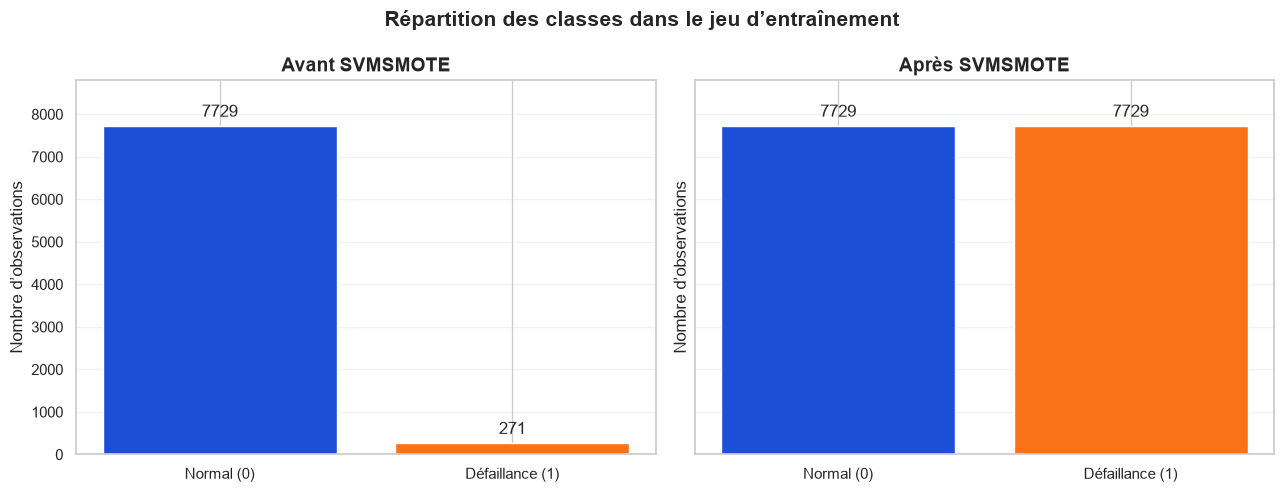

Figure et tableau exportés dans resultats_projet/


In [14]:
# Visualisation avant/après SVMSMOTE — uniquement sur l'entraînement
from sklearn.base import clone

# Le préprocesseur est ajusté uniquement sur X_train pour cette visualisation.
X_train_transforme = preprocessing().fit_transform(X_train)
visual_smote = SVMSMOTE(random_state=SEED, k_neighbors=3, m_neighbors=5)
X_train_illustre, y_train_illustre = visual_smote.fit_resample(X_train_transforme, y_train)

comptage_avant = pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0)
comptage_apres = pd.Series(y_train_illustre).value_counts().reindex([0, 1], fill_value=0)
resume_equilibrage = pd.DataFrame({
    'Classe': ['Normal (0)', 'Défaillance (1)'],
    'Avant SVMSMOTE': comptage_avant.to_numpy(),
    'Après SVMSMOTE': comptage_apres.to_numpy(),
})
resume_equilibrage['Avant (%)'] = (100 * resume_equilibrage['Avant SVMSMOTE'] / resume_equilibrage['Avant SVMSMOTE'].sum()).round(2)
resume_equilibrage['Après (%)'] = (100 * resume_equilibrage['Après SVMSMOTE'] / resume_equilibrage['Après SVMSMOTE'].sum()).round(2)
display(resume_equilibrage)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
max_count = max(comptage_avant.max(), comptage_apres.max())
for ax, comptes, titre in zip(axes, [comptage_avant, comptage_apres], ['Avant SVMSMOTE', 'Après SVMSMOTE']):
    barres = ax.bar(['Normal (0)', 'Défaillance (1)'], comptes.values, color=['#1D4ED8', '#F97316'])
    ax.bar_label(barres, padding=4, fmt='%d')
    ax.set_title(titre, fontsize=14, fontweight='bold')
    ax.set_ylim(0, max_count * 1.14)
    ax.set_ylabel('Nombre d’observations')
    ax.grid(axis='y', alpha=0.25)
plt.suptitle('Répartition des classes dans le jeu d’entraînement', fontsize=15, fontweight='bold')
plt.tight_layout()
# Sauvegarde pour le mémoire et le tableau de bord.
Path('resultats_projet').mkdir(exist_ok=True)
resume_equilibrage.to_csv('resultats_projet/equilibrage_avant_apres_svmsmote.csv', index=False)
fig.savefig('resultats_projet/equilibrage_avant_apres_svmsmote.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure et tableau exportés dans resultats_projet/')

## 3.2 — Validation croisée Stratified K-Fold (5 folds) sur l'entraînement

**Protocole (sans fuite de données)**
- La validation croisée est appliquée **uniquement sur `X_train` / `y_train`** (80 % des données). Le jeu de test (20 %) n'est ni utilisé, ni vu pendant cette étape.
- `StratifiedKFold(n_splits=5, shuffle=True)` conserve la proportion de pannes dans chaque fold.
- Le prétraitement (imputation, standardisation, encodage) **et** `SVMSMOTE` sont placés **dans le `Pipeline` imblearn** : à chaque fold, ils sont ajustés/appliqués sur les 4 folds d'apprentissage seulement. Le fold de validation n'est jamais rééquilibré ni utilisé pour ajuster le prétraitement.
- Les cinq modèles sont comparés avec les mêmes folds et les mêmes métriques (F1-score, Recall, Precision, ROC-AUC). **Le meilleur modèle est choisi sur la moyenne du F1-score en validation croisée**, et non sur le test.

In [15]:
# Validation croisée Stratified K-Fold (5 folds) — uniquement sur le jeu d'entraînement
from sklearn.base import clone

N_FOLDS = 5
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
scoring_cv = {'F1-score': 'f1', 'Recall': 'recall', 'Precision': 'precision', 'ROC-AUC': 'roc_auc'}
metriques_cv = list(scoring_cv)

# Contrôle de la stratification : proportion de pannes par fold (train interne / validation)
controle_folds = []
for k, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    controle_folds.append({'Fold': k, 'N entraînement': len(idx_tr), 'N validation': len(idx_val),
                           'Pannes validation': int(y_train.iloc[idx_val].sum()),
                           '% pannes validation': round(100 * y_train.iloc[idx_val].mean(), 2)})
display(pd.DataFrame(controle_folds).set_index('Fold'))
print('Taille du jeu de test (non utilisé ici) :', len(y_test))

cv_resultats_folds = []   # une ligne par (modèle, fold)
cv_duree = {}
for nom, estimateur in models.items():
    t0 = time.time()
    # SVMSMOTE est dans le Pipeline : il est donc réajusté dans chaque fold d'apprentissage
    pipeline_cv = build_pipeline(clone(estimateur), use_smote=True)
    scores = cross_validate(pipeline_cv, X_train, y_train, cv=cv, scoring=scoring_cv,
                            n_jobs=1, error_score='raise')
    cv_duree[nom] = time.time() - t0
    for k in range(N_FOLDS):
        ligne = {'Modèle': nom, 'Fold': k + 1}
        ligne.update({m: scores[f'test_{m}'][k] for m in metriques_cv})
        cv_resultats_folds.append(ligne)
    print(f'{nom:<20} F1 = {scores["test_F1-score"].mean():.4f} ± {scores["test_F1-score"].std(ddof=1):.4f}  ({cv_duree[nom]:.1f} s)')

cv_folds = pd.DataFrame(cv_resultats_folds)

,N entraînement,N validation,Pannes validation,% pannes validation
Fold,,,,
1,6400,1600,54,3.38
2,6400,1600,54,3.38
3,6400,1600,54,3.38
4,6400,1600,54,3.38
5,6400,1600,55,3.44


Taille du jeu de test (non utilisé ici) : 2000
Logistic Regression  F1 = 0.3331 ± 0.0199  (3.6 s)


C:\Users\med\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\med\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\med\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\med\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` param

SVM RBF              F1 = 0.5839 ± 0.0432  (61.0 s)
Random Forest        F1 = 0.7870 ± 0.0491  (12.7 s)
XGBoost              F1 = 0.7706 ± 0.0319  (6.7 s)
MLP                  F1 = 0.6578 ± 0.0491  (35.0 s)


### Tableau comparatif — scores moyens et écarts-types (validation croisée 5 folds)

In [16]:
# Moyenne et écart-type (ddof=1 entre folds) par modèle
agg = cv_folds.groupby('Modèle', sort=False)[metriques_cv].agg(['mean', 'std'])
cv_resume = pd.DataFrame(index=agg.index)
for m in metriques_cv:
    cv_resume[f'{m} (moy.)'] = agg[(m, 'mean')]
    cv_resume[f'{m} (écart-type)'] = agg[(m, 'std')]
cv_resume = cv_resume.sort_values('F1-score (moy.)', ascending=False)
cv_resume['Rang F1'] = np.arange(1, len(cv_resume) + 1)

# Version lisible « moyenne ± écart-type »
cv_affichage = pd.DataFrame({m: [f"{cv_resume.loc[n, f'{m} (moy.)']:.4f} ± {cv_resume.loc[n, f'{m} (écart-type)']:.4f}"
                                 for n in cv_resume.index] for m in metriques_cv}, index=cv_resume.index)
cv_affichage.insert(0, 'Rang (F1)', cv_resume['Rang F1'])
print('VALIDATION CROISÉE STRATIFIED K-FOLD (5) — moyenne ± écart-type, sur le train uniquement')
display(cv_affichage)
display(cv_resume.drop(columns='Rang F1').round(4))
print('Scores par fold :')
display(cv_folds.pivot(index='Modèle', columns='Fold', values='F1-score').loc[cv_resume.index].round(4).add_prefix('F1 fold '))

# Sélection du meilleur modèle : F1-score moyen en validation croisée (le test n'intervient pas)
selected_name_cv = cv_resume['F1-score (moy.)'].idxmax()
print(f"\n>>> Meilleur modèle selon le F1-score moyen en validation croisée : {selected_name_cv}")
meilleur = cv_resume.loc[selected_name_cv]
print(f"    F1 = {meilleur['F1-score (moy.)']:.4f} ± {meilleur['F1-score (écart-type)']:.4f} | "
      f"Recall = {meilleur['Recall (moy.)']:.4f} | Precision = {meilleur['Precision (moy.)']:.4f} | ROC-AUC = {meilleur['ROC-AUC (moy.)']:.4f}")
# Si l'écart entre les deux premiers est inférieur à un écart-type, on le signale honnêtement
if len(cv_resume) > 1:
    deux = cv_resume.iloc[:2]
    ecart = deux['F1-score (moy.)'].iloc[0] - deux['F1-score (moy.)'].iloc[1]
    if ecart < deux['F1-score (écart-type)'].iloc[0]:
        print(f"    Remarque : l'écart de F1 avec {deux.index[1]} ({ecart:.4f}) est inférieur à l'écart-type du premier : la différence n'est pas nette.")

VALIDATION CROISÉE STRATIFIED K-FOLD (5) — moyenne ± écart-type, sur le train uniquement


,Rang (F1),F1-score,Recall,Precision,ROC-AUC
Modèle,,,,,
Random Forest,1,0.7870 ± 0.0491,0.7713 ± 0.0617,0.8060 ± 0.0611,0.9733 ± 0.0141
XGBoost,2,0.7706 ± 0.0319,0.8411 ± 0.0318,0.7118 ± 0.0422,0.9781 ± 0.0114
MLP,3,0.6578 ± 0.0491,0.7787 ± 0.0286,0.5745 ± 0.0816,0.9646 ± 0.0117
SVM RBF,4,0.5839 ± 0.0432,0.8265 ± 0.0214,0.4528 ± 0.0506,0.9596 ± 0.0130
Logistic Regression,5,0.3331 ± 0.0199,0.7748 ± 0.0725,0.2124 ± 0.0130,0.9093 ± 0.0221


,F1-score (moy.),F1-score (écart-type),Recall (moy.),Recall (écart-type),Precision (moy.),Precision (écart-type),ROC-AUC (moy.),ROC-AUC (écart-type)
Modèle,,,,,,,,
Random Forest,0.7870,0.0491,0.7713,0.0617,0.8060,0.0611,0.9733,0.0141
XGBoost,0.7706,0.0319,0.8411,0.0318,0.7118,0.0422,0.9781,0.0114
MLP,0.6578,0.0491,0.7787,0.0286,0.5745,0.0816,0.9646,0.0117
SVM RBF,0.5839,0.0432,0.8265,0.0214,0.4528,0.0506,0.9596,0.0130
Logistic Regression,0.3331,0.0199,0.7748,0.0725,0.2124,0.0130,0.9093,0.0221


Scores par fold :


Fold,F1 fold 1,F1 fold 2,F1 fold 3,F1 fold 4,F1 fold 5
Modèle,,,,,
Random Forest,0.8288,0.7048,0.7818,0.8155,0.8039
XGBoost,0.7931,0.7273,0.7458,0.7965,0.7903
MLP,0.6466,0.6957,0.6331,0.7179,0.5957
SVM RBF,0.5542,0.5548,0.5500,0.6429,0.6174
Logistic Regression,0.3441,0.3128,0.3162,0.3320,0.3607



>>> Meilleur modèle selon le F1-score moyen en validation croisée : Random Forest
    F1 = 0.7870 ± 0.0491 | Recall = 0.7713 | Precision = 0.8060 | ROC-AUC = 0.9733
    Remarque : l'écart de F1 avec XGBoost (0.0164) est inférieur à l'écart-type du premier : la différence n'est pas nette.


### Visualisations de la validation croisée

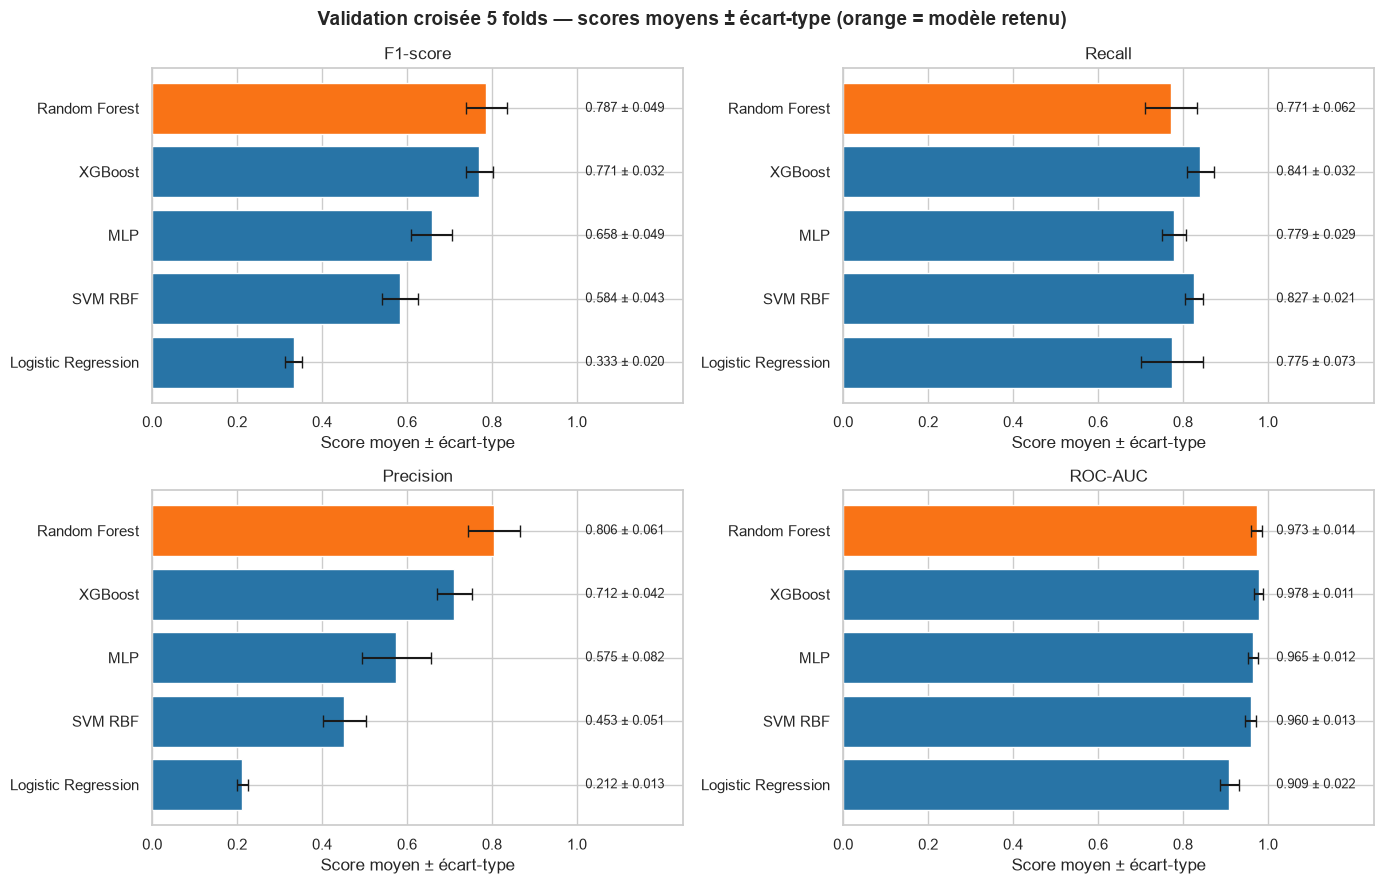

In [17]:
# 1) Scores moyens ± écart-type (barres d'erreur) pour les quatre métriques
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ordre = cv_resume.index.tolist()
for ax, m in zip(axes.flat, metriques_cv):
    moy = cv_resume.loc[ordre, f'{m} (moy.)']; sd = cv_resume.loc[ordre, f'{m} (écart-type)']
    couleurs = ['#F97316' if n == selected_name_cv else '#2874A6' for n in ordre]
    ax.barh(ordre, moy, xerr=sd, color=couleurs, capsize=4)
    for i, (v, s) in enumerate(zip(moy, sd)):
        ax.text(1.02, i, f'{v:.3f} ± {s:.3f}', va='center', fontsize=9)
    ax.set_xlim(0, 1.25); ax.set_xticks([0, .2, .4, .6, .8, 1]); ax.invert_yaxis(); ax.set_title(m); ax.set_xlabel('Score moyen ± écart-type')
plt.suptitle('Validation croisée 5 folds — scores moyens ± écart-type (orange = modèle retenu)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

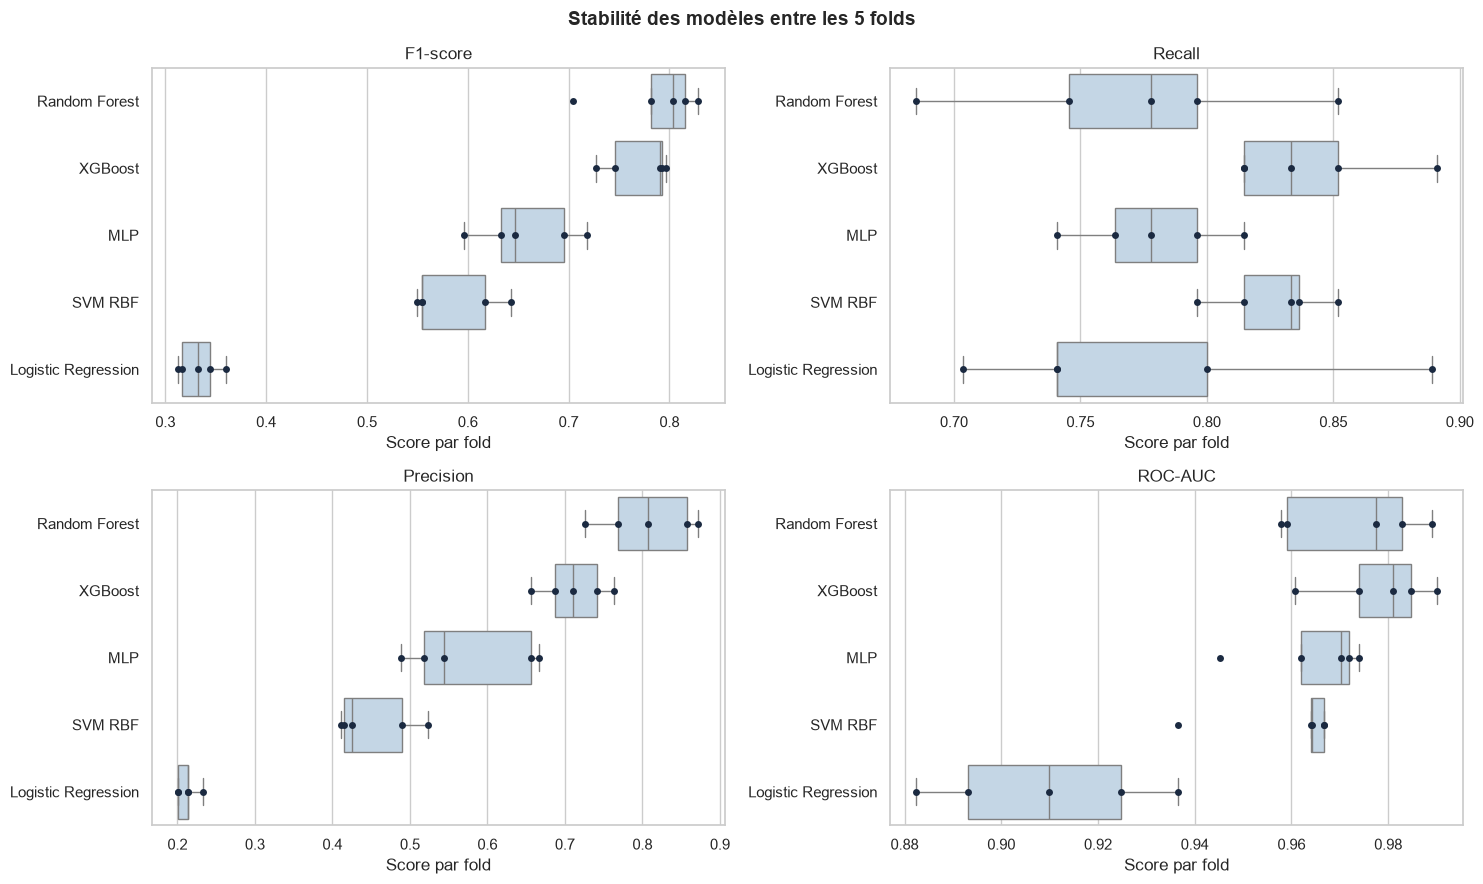

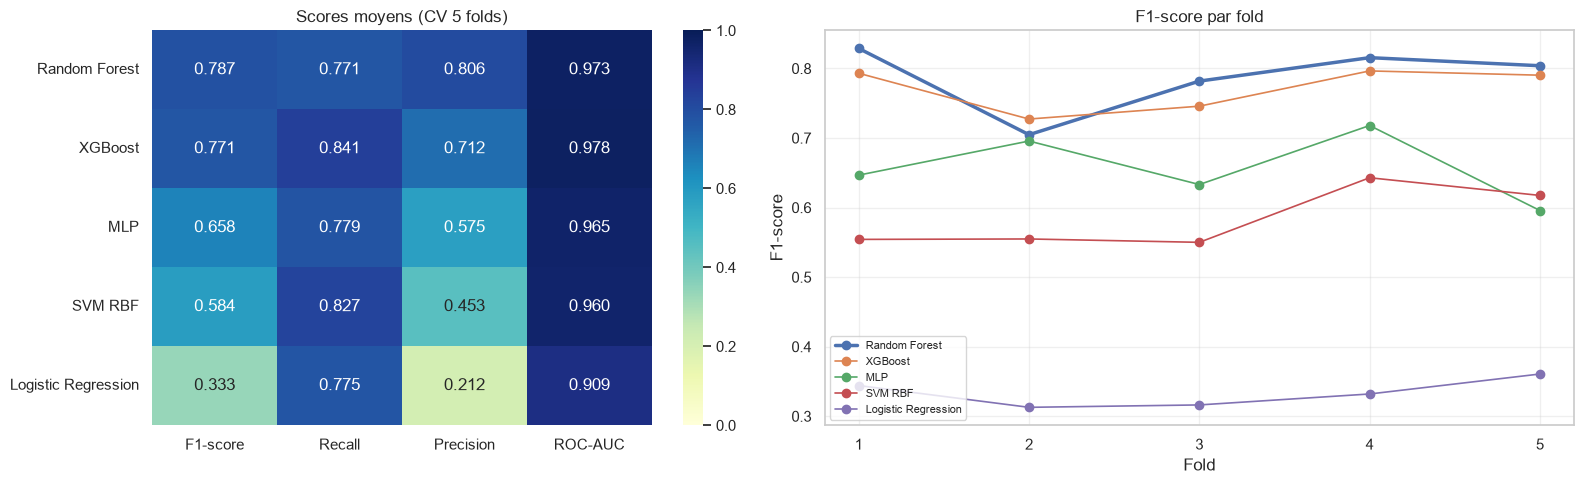

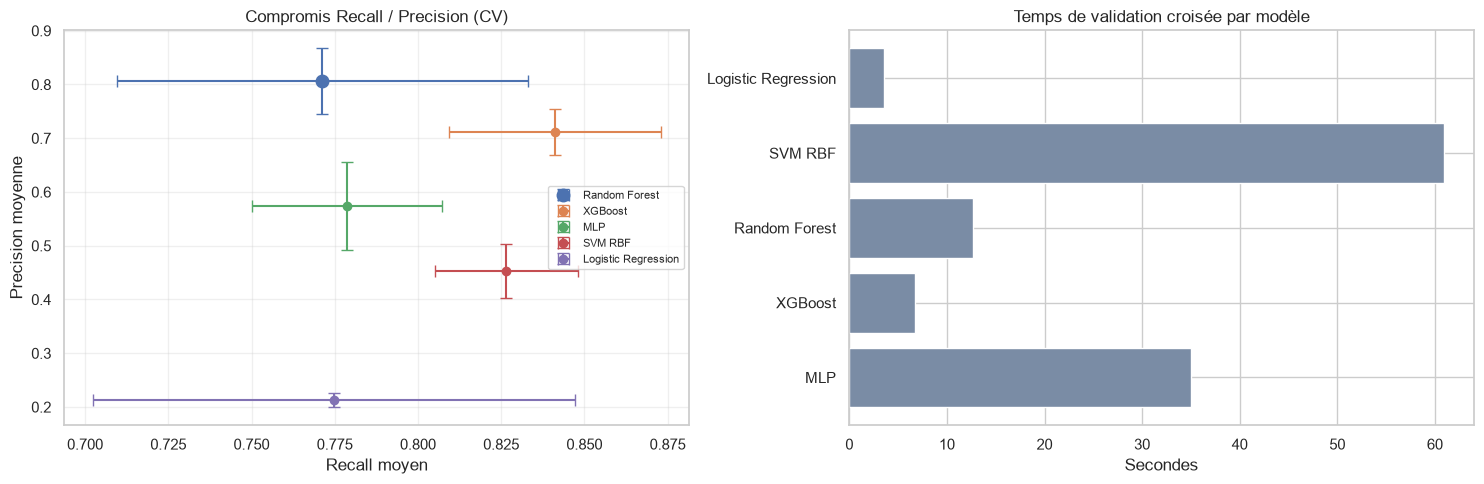

In [18]:
# 2) Dispersion des scores par fold (boîtes + points = un point par fold)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, m in zip(axes.flat, metriques_cv):
    sns.boxplot(data=cv_folds, x=m, y='Modèle', order=ordre, ax=ax, color='#BFD7EA', fliersize=0)
    sns.stripplot(data=cv_folds, x=m, y='Modèle', order=ordre, ax=ax, color='#1B2A41', size=5, jitter=False)
    ax.set_title(m); ax.set_ylabel(''); ax.set_xlabel('Score par fold')
plt.suptitle('Stabilité des modèles entre les 5 folds', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

# 3) Carte thermique des scores moyens + courbe F1 par fold
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.2]})
sns.heatmap(cv_resume.loc[ordre, [f'{m} (moy.)' for m in metriques_cv]].set_axis(metriques_cv, axis=1),
            annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Scores moyens (CV 5 folds)'); axes[0].set_ylabel('')
for nom in ordre:
    d = cv_folds[cv_folds['Modèle'] == nom]
    axes[1].plot(d['Fold'], d['F1-score'], marker='o', label=nom, lw=2.5 if nom == selected_name_cv else 1.2)
axes[1].set(title='F1-score par fold', xlabel='Fold', ylabel='F1-score', xticks=range(1, N_FOLDS + 1)); axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

# 4) Compromis Recall / Precision (moyenne ± écart-type) et temps de calcul
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for nom in ordre:
    r = cv_resume.loc[nom]
    axes[0].errorbar(r['Recall (moy.)'], r['Precision (moy.)'], xerr=r['Recall (écart-type)'], yerr=r['Precision (écart-type)'],
                     fmt='o', capsize=4, ms=9 if nom == selected_name_cv else 6, label=nom)
axes[0].set(title='Compromis Recall / Precision (CV)', xlabel='Recall moyen', ylabel='Precision moyenne'); axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)
axes[1].barh(list(cv_duree), list(cv_duree.values()), color='#7A8CA5'); axes[1].invert_yaxis()
axes[1].set(title='Temps de validation croisée par modèle', xlabel='Secondes')
plt.tight_layout(); plt.show()

In [19]:
# Export des résultats de validation croisée
out = Path('resultats_projet'); out.mkdir(exist_ok=True)
cv_folds.to_csv(out / 'cv_scores_par_fold.csv', index=False)
cv_resume.to_csv(out / 'cv_resume_moyenne_ecarttype.csv')
fig.savefig(out / 'cv_recall_precision_temps.png', dpi=200, bbox_inches='tight')
print('Résultats CV exportés dans', out.resolve())

Résultats CV exportés dans C:\Users\med\Desktop\testing\resultats_projet


## 4 — Entraînement final des cinq modèles et évaluation sur le test

La validation croisée (section 3.2) a servi à **comparer les modèles et à choisir le meilleur** sur l’entraînement uniquement. Ici, chaque modèle est réentraîné **une seule fois** sur l’ensemble du jeu d’entraînement, avec le même SVMSMOTE intégré au pipeline, puis évalué **une seule fois** sur le jeu de test indépendant (20 %, non rééquilibré). Le test ne sert qu’à l’évaluation finale : le modèle retenu est celui désigné par la validation croisée, quel que soit son classement sur le test. Aucune recherche d’hyperparamètres n’est utilisée.

In [20]:
# Entraînement final des cinq modèles — SVMSMOTE uniquement sur le train
from sklearn.base import clone
comparaison_lignes = []
predictions_modeles = {}
modeles_entraines = {}
for nom, estimateur in models.items():
    print('Entraînement :', nom)
    pipeline = build_pipeline(clone(estimateur), use_smote=True)
    pipeline.fit(X_train, y_train)
    modeles_entraines[nom] = pipeline
    probabilites = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilites >= 0.5).astype(int)
    predictions_modeles[nom] = {'y_pred': predictions, 'y_proba': probabilites}
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    comparaison_lignes.append({
        'Modèle': nom, 'SVMSMOTE': True,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-score': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilites),
        'Average Precision': average_precision_score(y_test, probabilites),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })
comparaison_test = pd.DataFrame(comparaison_lignes)
display(comparaison_test.set_index('Modèle').round(4))
# Sélection du modèle : issue de la VALIDATION CROISÉE (section 3.2), pas du test.
selected_name = selected_name_cv
final_model = modeles_entraines[selected_name]
test_proba = predictions_modeles[selected_name]['y_proba']
test_pred = predictions_modeles[selected_name]['y_pred']
selected_balance = True
metrics = {'Accuracy': accuracy_score(y_test, test_pred),
           'Précision': precision_score(y_test, test_pred, zero_division=0),
           'Rappel': recall_score(y_test, test_pred, zero_division=0),
           'F1': f1_score(y_test, test_pred, zero_division=0),
           'ROC-AUC': roc_auc_score(y_test, test_proba),
           'Average Precision': average_precision_score(y_test, test_proba)}
print('Modèle retenu par validation croisée :', selected_name)
meilleur_f1_test = comparaison_test.sort_values('F1-score', ascending=False).iloc[0]['Modèle']
print('Pour information, meilleur F1 observé sur le test :', meilleur_f1_test, '(non utilisé pour la sélection)')
display(pd.Series(metrics, name='Valeur').to_frame().round(4))
print(classification_report(y_test, test_pred, zero_division=0))

Entraînement : Logistic Regression
Entraînement : SVM RBF


C:\Users\med\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Entraînement : Random Forest
Entraînement : XGBoost
Entraînement : MLP


,SVMSMOTE,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,TN,FP,FN,TP
Modèle,,,,,,,,,,,
Logistic Regression,True,0.9010,0.2314,0.8235,0.3613,0.9188,0.4426,1746,186,12,56
SVM RBF,True,0.9595,0.4496,0.8529,0.5888,0.9677,0.6956,1861,71,10,58
Random Forest,True,0.9880,0.8235,0.8235,0.8235,0.9741,0.8653,1920,12,12,56
XGBoost,True,0.9825,0.7089,0.8235,0.7619,0.9667,0.8804,1909,23,12,56
MLP,True,0.9700,0.5392,0.8088,0.6471,0.9720,0.7226,1885,47,13,55


Modèle retenu par validation croisée : Random Forest
Pour information, meilleur F1 observé sur le test : Random Forest (non utilisé pour la sélection)


,Valeur
Accuracy,0.9880
Précision,0.8235
Rappel,0.8235
F1,0.8235
ROC-AUC,0.9741
Average Precision,0.8653


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.82      0.82      0.82        68

    accuracy                           0.99      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.99      0.99      0.99      2000



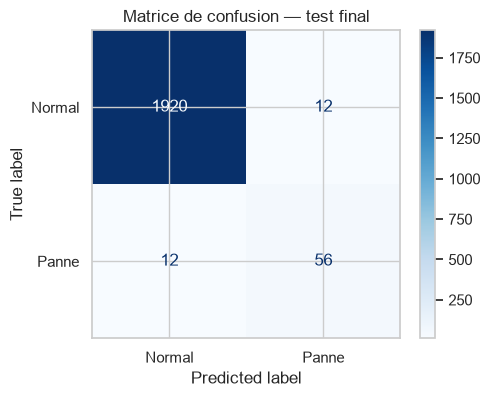

Pannes détectées : 56 | Pannes manquées (FN) : 12 | Fausses alertes (FP) : 12


In [21]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['Normal','Panne'],cmap='Blues',ax=ax)
ax.set_title('Matrice de confusion — test final');plt.show()
tn,fp,fn,tp=confusion_matrix(y_test,test_pred).ravel()
print(f'Pannes détectées : {tp} | Pannes manquées (FN) : {fn} | Fausses alertes (FP) : {fp}')

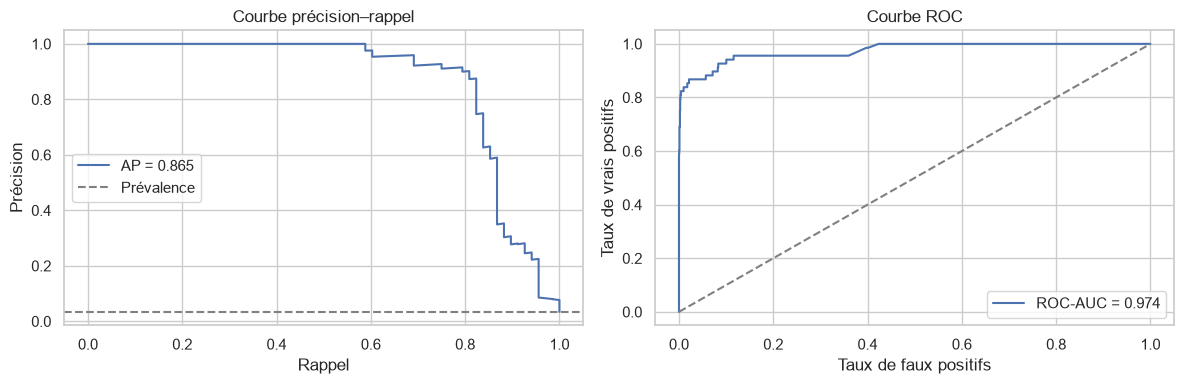

In [22]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
p,r,_=precision_recall_curve(y_test,test_proba)
axs[0].plot(r,p,label=f"AP = {metrics['Average Precision']:.3f}");axs[0].axhline(y_test.mean(),ls='--',color='gray',label='Prévalence');axs[0].set(xlabel='Rappel',ylabel='Précision',title='Courbe précision–rappel');axs[0].legend()
fpr,tpr,_=roc_curve(y_test,test_proba)
axs[1].plot(fpr,tpr,label=f"ROC-AUC = {metrics['ROC-AUC']:.3f}");axs[1].plot([0,1],[0,1],'--',color='gray');axs[1].set(xlabel='Taux de faux positifs',ylabel='Taux de vrais positifs',title='Courbe ROC');axs[1].legend();plt.tight_layout();plt.show()

## 5 — Comparaison des cinq modèles sur le test

Tous les modèles ont été entraînés sur le jeu d’entraînement rééquilibré avec SVMSMOTE (intégré au pipeline). Le tableau et les matrices ci-dessous proviennent **des prédictions calculées dans la section 4** sur le test indépendant, qui n’a pas été rééquilibré. Le tableau de validation croisée (section 3.2) est rappelé pour comparer la performance estimée en CV et la performance finale sur le test.

In [23]:
print('COMPARAISON DES CINQ MODÈLES — TEST NON RÉÉQUILIBRÉ')
display(comparaison_test.set_index('Modèle').round(4))
print('\nRAPPEL — F1-score moyen en validation croisée (train) vs F1-score sur le test')
comparaison_cv_test = pd.DataFrame({
    'F1 CV (moy.)': cv_resume['F1-score (moy.)'], 'F1 CV (écart-type)': cv_resume['F1-score (écart-type)'],
    'F1 test': comparaison_test.set_index('Modèle')['F1-score']}).loc[cv_resume.index]
comparaison_cv_test['Écart test − CV'] = comparaison_cv_test['F1 test'] - comparaison_cv_test['F1 CV (moy.)']
display(comparaison_cv_test.round(4))


COMPARAISON DES CINQ MODÈLES — TEST NON RÉÉQUILIBRÉ


,SVMSMOTE,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,TN,FP,FN,TP
Modèle,,,,,,,,,,,
Logistic Regression,True,0.9010,0.2314,0.8235,0.3613,0.9188,0.4426,1746,186,12,56
SVM RBF,True,0.9595,0.4496,0.8529,0.5888,0.9677,0.6956,1861,71,10,58
Random Forest,True,0.9880,0.8235,0.8235,0.8235,0.9741,0.8653,1920,12,12,56
XGBoost,True,0.9825,0.7089,0.8235,0.7619,0.9667,0.8804,1909,23,12,56
MLP,True,0.9700,0.5392,0.8088,0.6471,0.9720,0.7226,1885,47,13,55



RAPPEL — F1-score moyen en validation croisée (train) vs F1-score sur le test


,F1 CV (moy.),F1 CV (écart-type),F1 test,Écart test − CV
Modèle,,,,
Random Forest,0.7870,0.0491,0.8235,0.0366
XGBoost,0.7706,0.0319,0.7619,-0.0087
MLP,0.6578,0.0491,0.6471,-0.0108
SVM RBF,0.5839,0.0432,0.5888,0.0050
Logistic Regression,0.3331,0.0199,0.3613,0.0282


### 8.1 — Comparaison visuelle des métriques

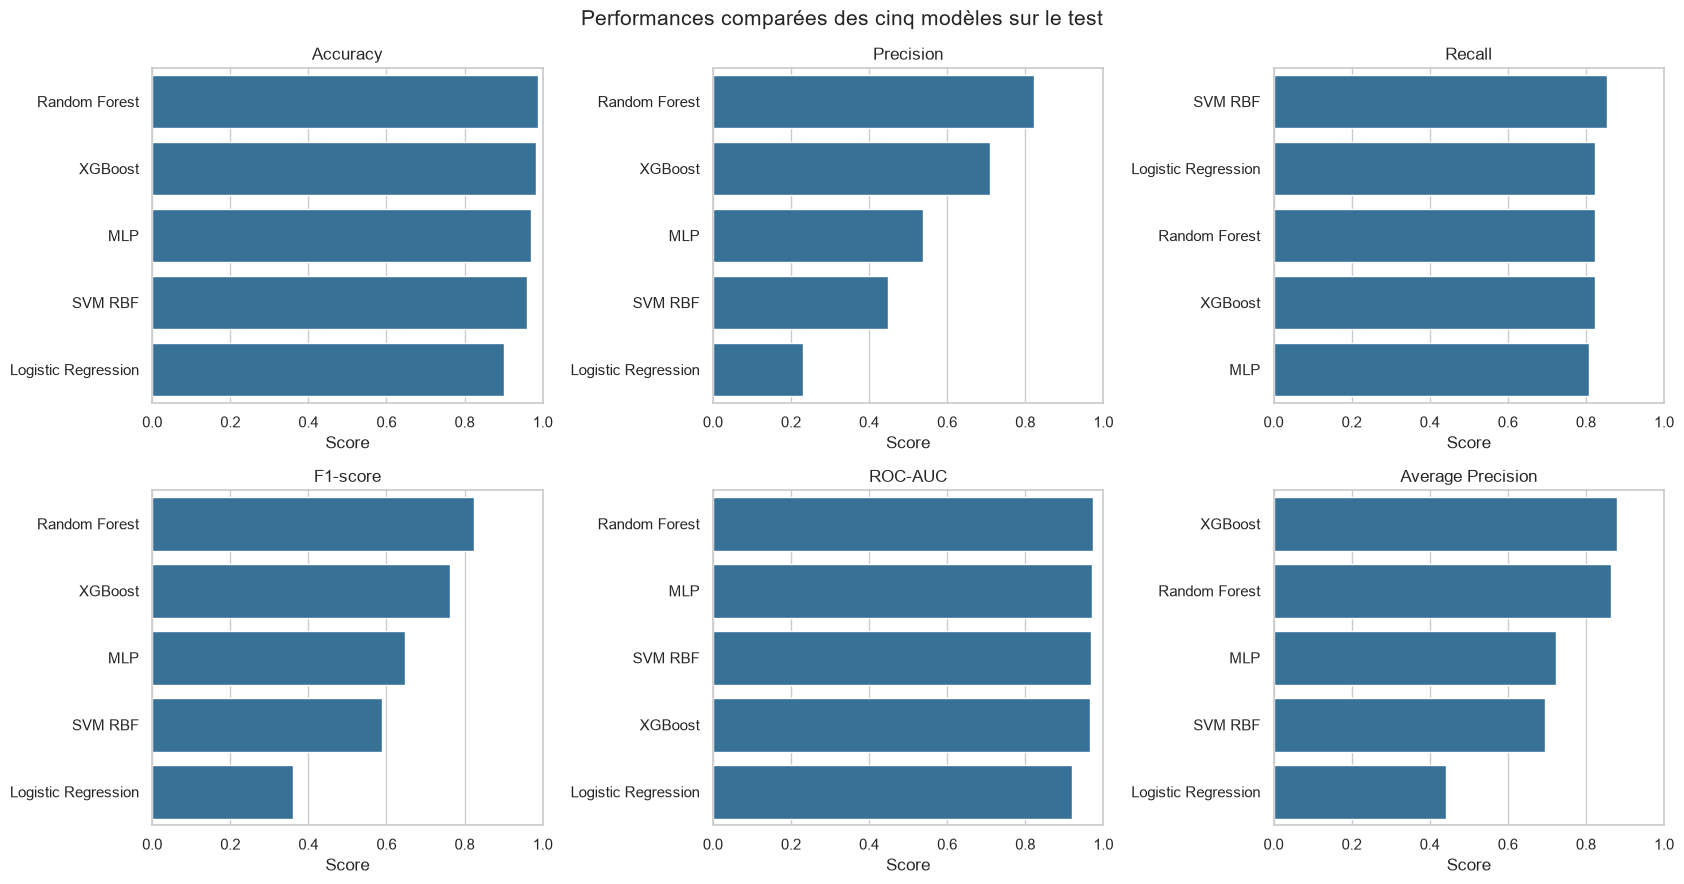

In [24]:
metriques_comparaison = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'Average Precision']
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, metrique in zip(axes.flat, metriques_comparaison):
    classement = comparaison_test.sort_values(metrique, ascending=False)
    sns.barplot(data=classement, x=metrique, y='Modèle', ax=ax, color='#2874A6')
    ax.set_xlim(0, 1)
    ax.set_title(metrique)
    ax.set_xlabel('Score')
    ax.set_ylabel('')
plt.suptitle('Performances comparées des cinq modèles sur le test', fontsize=15)
plt.tight_layout()
plt.show()


### 8.2 — Matrices de confusion des cinq modèles

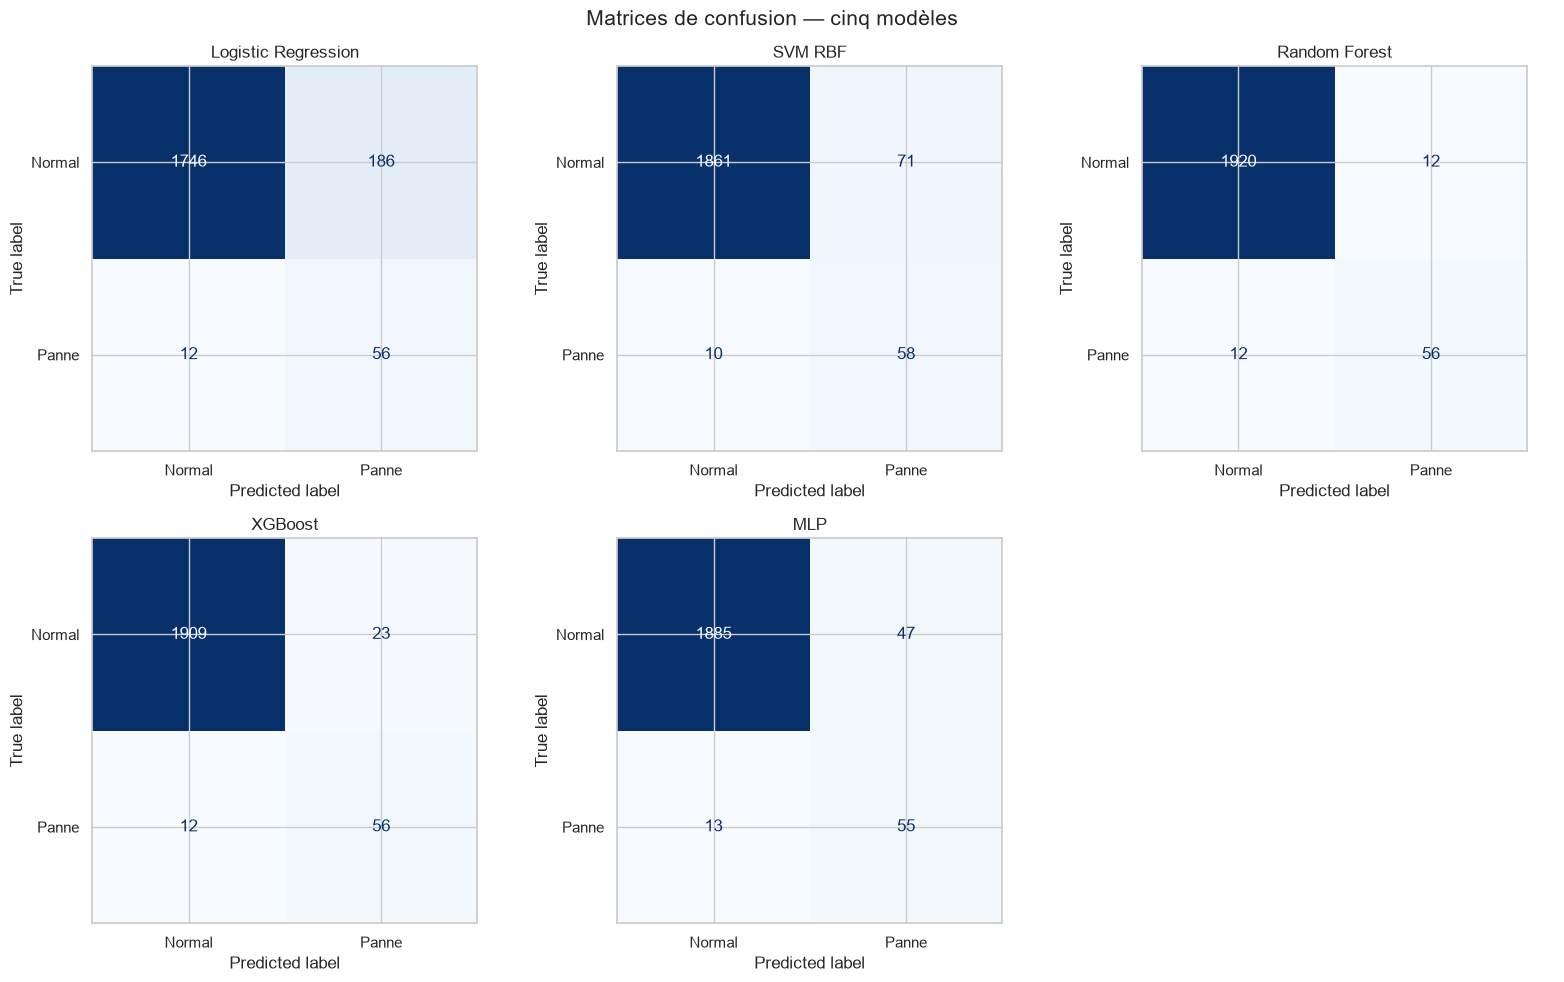

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (nom, resultat) in zip(axes.flat, predictions_modeles.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, resultat['y_pred'], labels=[0, 1],
        display_labels=['Normal', 'Panne'], cmap='Blues',
        colorbar=False, ax=ax, values_format='d'
    )
    ax.set_title(nom)
for ax in list(axes.flat)[len(predictions_modeles):]:
    ax.axis('off')
plt.suptitle('Matrices de confusion — cinq modèles', fontsize=15)
plt.tight_layout()
plt.show()


### 8.3 — Courbes ROC et précision–rappel comparatives

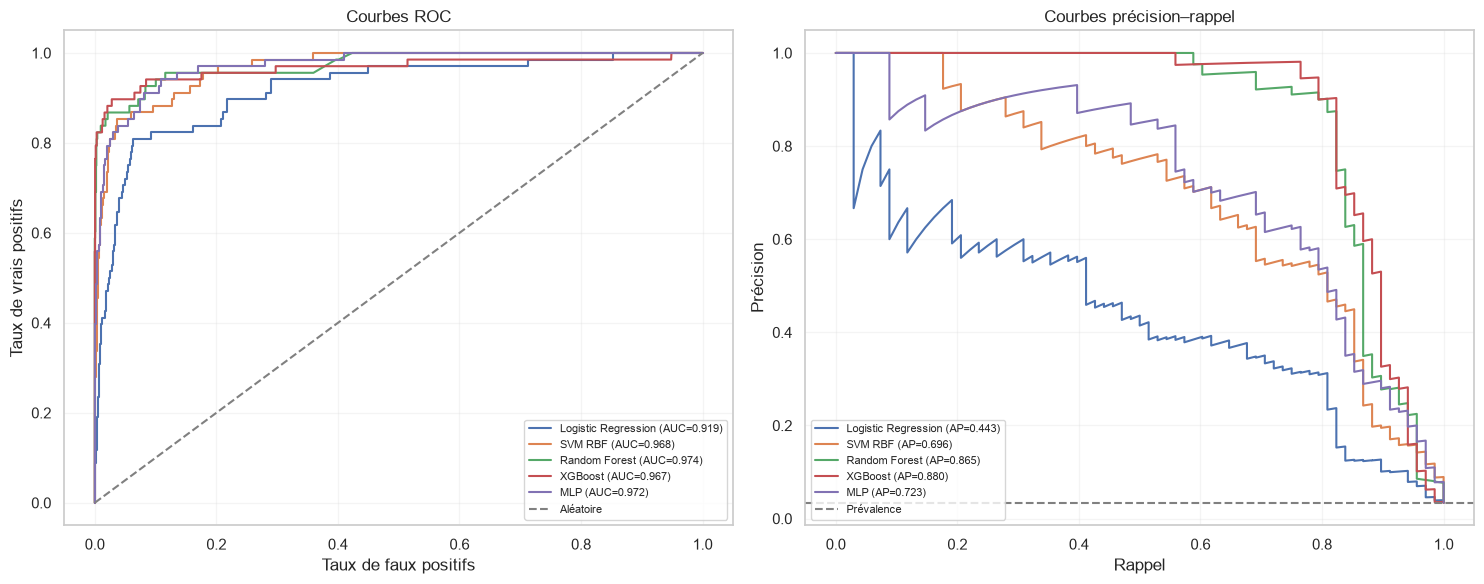

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for nom, resultat in predictions_modeles.items():
    proba = resultat['y_proba']
    fpr, tpr, _ = roc_curve(y_test, proba)
    p, r, _ = precision_recall_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{nom} (AUC={auc:.3f})')
    axes[1].plot(r, p, label=f'{nom} (AP={ap:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Aléatoire')
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='Prévalence')
axes[0].set(title='Courbes ROC', xlabel='Taux de faux positifs', ylabel='Taux de vrais positifs')
axes[1].set(title='Courbes précision–rappel', xlabel='Rappel', ylabel='Précision')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 8.4 — Export des tableaux comparatifs pour le rapport et Streamlit

In [27]:
out = Path('resultats_projet')
out.mkdir(exist_ok=True)
comparaison_test.to_csv(out / 'comparaison_5_modeles_test.csv', index=False)
for nom, resultat in predictions_modeles.items():
    nom_fichier = nom.lower().replace(' ', '_').replace('-', '_')
    matrice = confusion_matrix(y_test, resultat['y_pred'], labels=[0, 1])
    pd.DataFrame(matrice, index=['Reel_Normal', 'Reel_Panne'],
                 columns=['Predit_Normal', 'Predit_Panne']).to_csv(out / f'matrice_{nom_fichier}.csv')
print('Tableau et matrices exportés dans', out.resolve())


Tableau et matrices exportés dans C:\Users\med\Desktop\testing\resultats_projet


In [28]:
# Bilan opérationnel du modèle retenu
cm_finale = confusion_matrix(y_test, test_pred, labels=[0,1])
tn, fp, fn, tp = cm_finale.ravel()
bilan_metier = pd.DataFrame({
    'Indicateur': ['Pannes détectées (TP)', 'Pannes manquées (FN)', 'Fausses alertes (FP)', 'Normaux correctement identifiés (TN)', 'Prévalence des pannes (%)'],
    'Valeur': [tp, fn, fp, tn, round(100 * y_test.mean(), 2)]
})
display(bilan_metier)
print('Interprétation : le coût réel des FN et FP dépend de la criticité de la machine et de la politique de maintenance.')

,Indicateur,Valeur
0,Pannes détectées (TP),56.0
1,Pannes manquées (FN),12.0
2,Fausses alertes (FP),12.0
3,Normaux correctement identifiés (TN),1920.0
4,Prévalence des pannes (%),3.4


Interprétation : le coût réel des FN et FP dépend de la criticité de la machine et de la politique de maintenance.


## 9 — Analyse des erreurs et interprétabilité

In [29]:
errors=X_test.copy();errors['Réel']=y_test.to_numpy();errors['Prédit']=test_pred;errors['Probabilité de panne']=test_proba
print('Exemples de pannes manquées :');display(errors[(errors['Réel']==1)&(errors['Prédit']==0)].head(10))
print('Exemples de fausses alertes :');display(errors[(errors['Réel']==0)&(errors['Prédit']==1)].head(10))

Exemples de pannes manquées :


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Delta temperature [K],Power proxy [W],Type,Réel,Prédit,Probabilité de panne
9174,297.8,308.9,1871,25.6,200,11.1,5015.824943,L,1,0,0.002500
2671,299.7,309.3,1399,41.9,221,9.6,6138.473078,M,1,0,0.061417
2864,300.6,309.4,1380,47.6,246,8.8,6878.831274,H,1,0,0.312609
3695,302.2,311.3,1530,37.3,207,9.1,5976.251705,L,1,0,0.032738
7087,300.6,310.3,1648,30.5,217,9.7,5263.633771,L,1,0,0.058750
2941,300.7,309.6,1996,19.8,203,8.9,4138.608498,M,1,0,0.044381
9015,297.2,308.1,1431,49.7,210,10.9,7447.742288,L,1,0,0.281812
4778,303.6,312.2,1371,54.6,112,8.6,7838.964821,H,1,0,0.421166
7849,300.3,311.7,1374,47.9,222,11.4,6892.088795,M,1,0,0.079780
8506,298.4,309.6,1710,27.3,163,11.2,4888.632328,L,1,0,0.002500


Exemples de fausses alertes :


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Delta temperature [K],Power proxy [W],Type,Réel,Prédit,Probabilité de panne
4231,302.2,310.8,1340,47.8,54,8.6,6707.509755,L,0,1,0.781630
4381,301.9,309.6,1446,43.2,225,7.7,6541.549887,L,0,1,0.508405
4028,302.0,310.9,1455,43.2,220,8.9,6582.264928,L,0,1,0.580864
4754,303.3,311.5,1384,54.8,48,8.2,7942.281331,M,0,1,0.609202
4384,301.8,309.6,1443,42.7,231,7.8,6452.422903,L,0,1,0.552770
3794,302.2,310.8,1356,48.3,36,8.6,6858.599418,M,0,1,0.799667
7677,300.6,311.7,1428,52.6,208,11.1,7865.794022,L,0,1,0.684167
7086,300.6,310.4,2514,13.4,215,9.8,3527.757223,L,0,1,0.531671
4031,302.0,310.8,1447,42.7,229,8.8,6470.309038,L,0,1,0.541697
417,297.4,308.4,1394,50.1,213,11.0,7313.564866,L,0,1,0.512847


,Variable,Importance moyenne,Écart-type
2,Rotational speed [rpm],0.414497,0.026072
5,Delta temperature [K],0.284469,0.024450
4,Tool wear [min],0.248452,0.020047
3,Torque [Nm],0.136381,0.023364
6,Power proxy [W],0.125980,0.018284
7,Type,0.046116,0.011527
0,Air temperature [K],0.012437,0.007323
1,Process temperature [K],-0.001755,0.004724


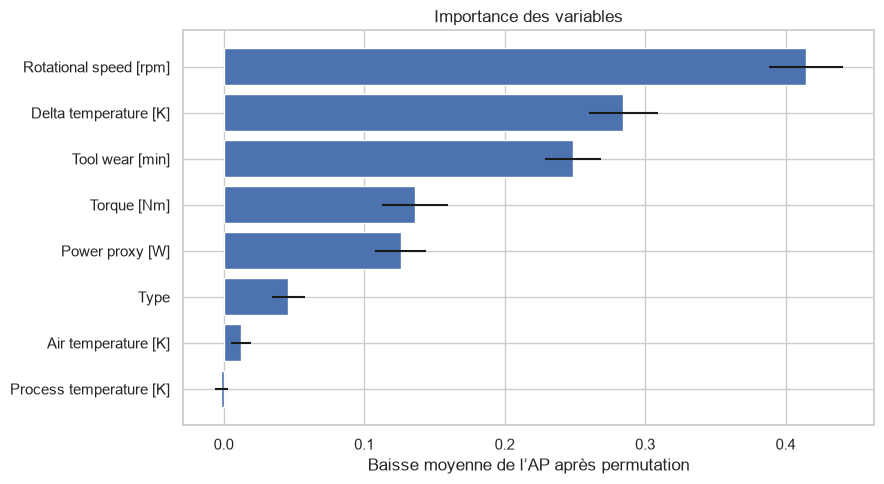

In [30]:
# Importance par permutation sur le jeu de test (analyse descriptive, sans retoucher le modèle)
importance=permutation_importance(final_model,X_test,y_test,n_repeats=5,scoring='average_precision',random_state=SEED,n_jobs=1)
imp=pd.DataFrame({'Variable':X_test.columns,'Importance moyenne':importance.importances_mean,'Écart-type':importance.importances_std}).sort_values('Importance moyenne')
display(imp.sort_values('Importance moyenne',ascending=False))
plt.figure(figsize=(9,5));plt.barh(imp['Variable'],imp['Importance moyenne'],xerr=imp['Écart-type']);plt.xlabel('Baisse moyenne de l’AP après permutation');plt.title('Importance des variables');plt.tight_layout();plt.show()

## 9.1 — Explications SHAP sur trois cas sélectionnés

SHAP décrit localement l’influence des variables sur les prédictions pour un vrai positif, un faux négatif et un faux positif lorsqu’ils existent. Le graphique récapitulatif concerne **uniquement ces quelques cas**, et ne doit pas être présenté comme une importance globale mesurée sur tout le test.


C:\Users\med\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Cas,Vérité,Prédiction,Probabilité de panne
0,Panne correctement détectée (TP),1,1,0.798821
1,Panne non détectée (FN),1,0,0.002500
2,Fausse alerte (FP),0,1,0.781630



SHAP Waterfall — Panne correctement détectée (TP)


,Variable transformée,Contribution SHAP,Impact_absolu
5,num__Delta temperature [K],0.382215,0.382215
2,num__Rotational speed [rpm],0.325272,0.325272
0,num__Air temperature [K],0.042520,0.042520
4,num__Tool wear [min],-0.028906,0.028906
3,num__Torque [Nm],0.028043,0.028043
1,num__Process temperature [K],-0.021579,0.021579
6,num__Power proxy [W],0.002156,0.002156
8,cat__Type_L,-0.000678,0.000678
7,cat__Type_H,-0.000132,0.000132
9,cat__Type_M,-0.000088,0.000088


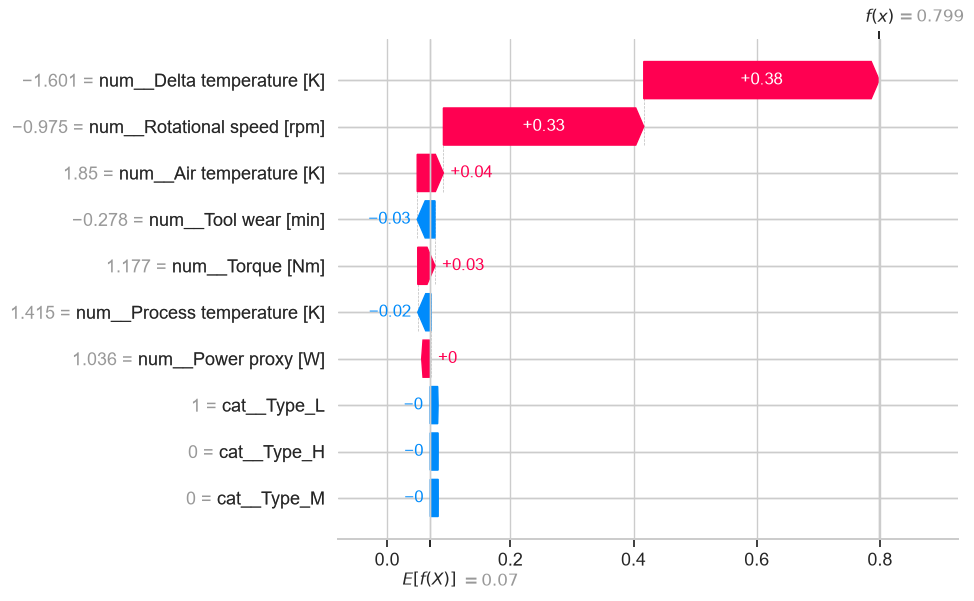


SHAP Waterfall — Panne non détectée (FN)


,Variable transformée,Contribution SHAP,Impact_absolu
3,num__Torque [Nm],-0.023055,0.023055
2,num__Rotational speed [rpm],-0.022535,0.022535
5,num__Delta temperature [K],-0.017986,0.017986
4,num__Tool wear [min],0.009785,0.009785
6,num__Power proxy [W],-0.007298,0.007298
0,num__Air temperature [K],-0.006289,0.006289
8,cat__Type_L,0.003646,0.003646
1,num__Process temperature [K],-0.003117,0.003117
7,cat__Type_H,-0.000558,0.000558
9,cat__Type_M,-0.000089,0.000089


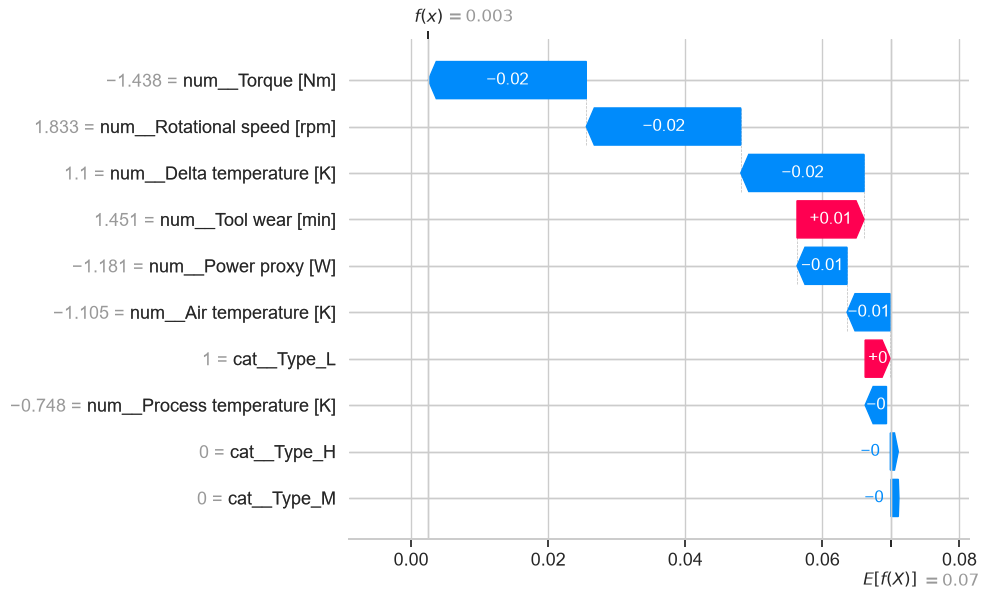


SHAP Waterfall — Fausse alerte (FP)


,Variable transformée,Contribution SHAP,Impact_absolu
5,num__Delta temperature [K],0.241740,0.241740
2,num__Rotational speed [rpm],0.189309,0.189309
0,num__Air temperature [K],0.128201,0.128201
3,num__Torque [Nm],0.074684,0.074684
1,num__Process temperature [K],0.045029,0.045029
6,num__Power proxy [W],0.016083,0.016083
8,cat__Type_L,0.007504,0.007504
4,num__Tool wear [min],0.004999,0.004999
7,cat__Type_H,0.002194,0.002194
9,cat__Type_M,0.001889,0.001889


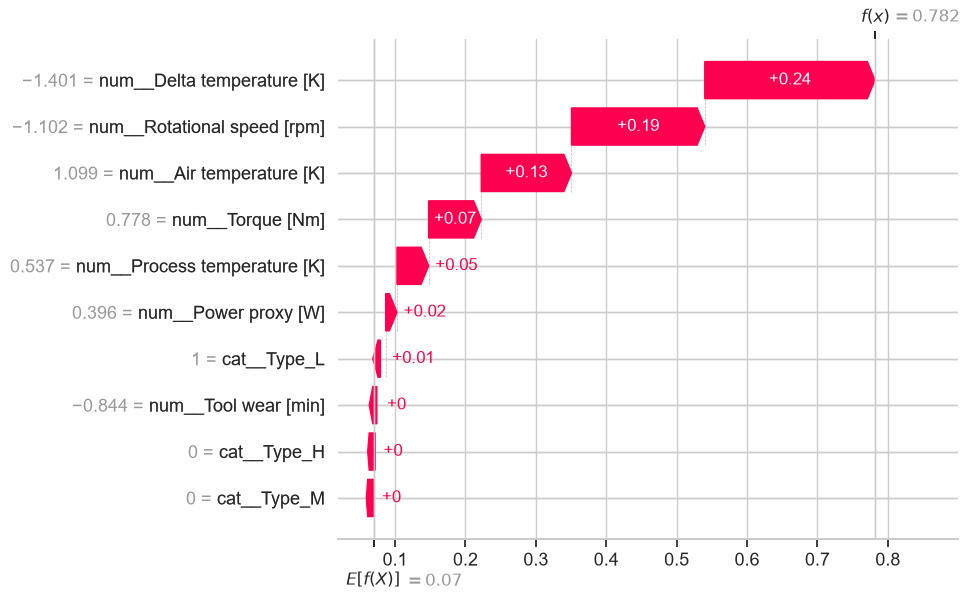

Importance moyenne absolue — sur les 3 cas choisis (pas sur tout le test)


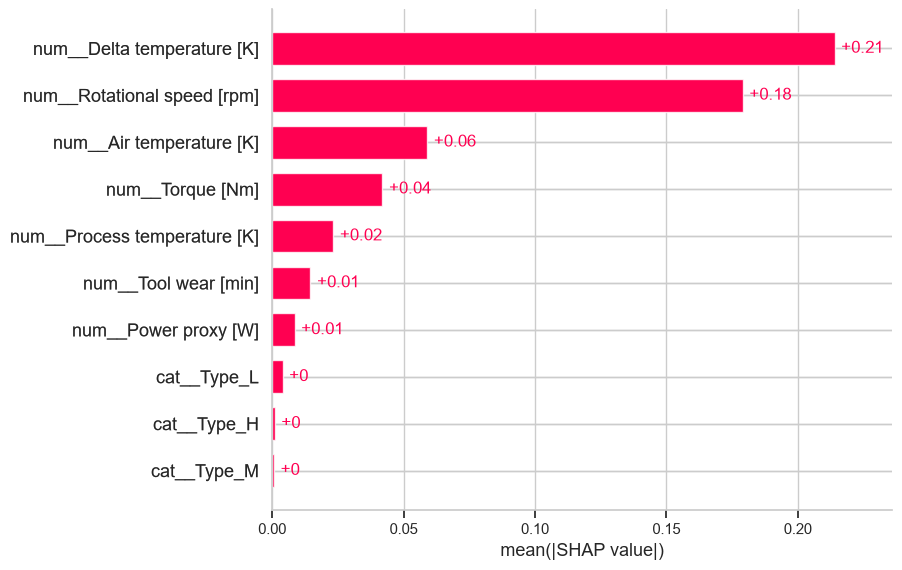

In [31]:
# SHAP — observations réelles du test, prétraitement identique au modèle final
import shap
from sklearn.metrics import confusion_matrix

preproc_final = final_model.named_steps['preprocess']
estimateur_final = final_model.named_steps['model']

# Matrices transformées par le prétraitement déjà ajusté
X_train_trans = np.asarray(preproc_final.transform(X_train), dtype=float)
X_test_trans = np.asarray(preproc_final.transform(X_test), dtype=float)
try:
    noms_variables_shap = list(preproc_final.get_feature_names_out())
except Exception:
    noms_variables_shap = [f'Variable {i+1}' for i in range(X_train_trans.shape[1])]

# Identifier les vrais positifs, faux négatifs et faux positifs du jeu de test
reel = np.asarray(y_test).astype(int)
predit = np.asarray(test_pred).astype(int)
cas_possibles = {
    'Panne correctement détectée (TP)': np.flatnonzero((reel == 1) & (predit == 1)),
    'Panne non détectée (FN)': np.flatnonzero((reel == 1) & (predit == 0)),
    'Fausse alerte (FP)': np.flatnonzero((reel == 0) & (predit == 1)),
}
indices_expliques = []
etiquettes_expliquees = []
for libelle, positions in cas_possibles.items():
    if len(positions):
        indices_expliques.append(int(positions[0]))
        etiquettes_expliquees.append(libelle)
    else:
        print('Cas absent du test :', libelle)
if not indices_expliques:
    indices_expliques = [0]
    etiquettes_expliquees = ['Première observation du test']

rng = np.random.default_rng(SEED)
positions_fond = rng.choice(len(X_train_trans), size=min(30, len(X_train_trans)), replace=False)
fond_shap = pd.DataFrame(X_train_trans[positions_fond], columns=noms_variables_shap)
exemples_shap = pd.DataFrame(X_test_trans[indices_expliques], columns=noms_variables_shap)

def probabilite_panne_shap(z):
    z = np.asarray(z, dtype=float)
    return estimateur_final.predict_proba(z)[:, 1]

explainer = shap.Explainer(probabilite_panne_shap, fond_shap, algorithm='permutation')
valeurs_shap = explainer(exemples_shap, max_evals=2 * exemples_shap.shape[1] + 1)

resume_shap = pd.DataFrame({
    'Cas': etiquettes_expliquees,
    'Vérité': reel[indices_expliques],
    'Prédiction': predit[indices_expliques],
    'Probabilité de panne': test_proba[indices_expliques]
})
display(resume_shap)
for i, libelle in enumerate(etiquettes_expliquees):
    print('\nSHAP Waterfall —', libelle)
    display(pd.DataFrame({
        'Variable transformée': noms_variables_shap,
        'Contribution SHAP': valeurs_shap.values[i]
    }).assign(Impact_absolu=lambda d: d['Contribution SHAP'].abs())
      .sort_values('Impact_absolu', ascending=False).head(12))
    shap.plots.waterfall(valeurs_shap[i], max_display=15, show=True)

print('Importance moyenne absolue — sur les', len(indices_expliques), 'cas choisis (pas sur tout le test)')
shap.plots.bar(valeurs_shap, max_display=15, show=True)


## 11 — Export reproductible des résultats et du modèle

In [32]:
out = Path('resultats_projet'); out.mkdir(exist_ok=True)
comparaison_test.to_csv(out / 'comparaison_5_modeles_test.csv', index=False)
resume_equilibrage.to_csv(out / 'equilibrage_avant_apres_svmsmote.csv', index=False)
pd.Series(metrics, name='Valeur').to_csv(out / 'metriques_test.csv')
bilan_metier.to_csv(out / 'bilan_metier.csv', index=False)
cv_resume.to_csv(out / 'cv_resume_moyenne_ecarttype.csv')
cv_folds.to_csv(out / 'cv_scores_par_fold.csv', index=False)
joblib.dump(final_model, out / 'modele_retenu.joblib')
print('Exports enregistrés dans :', out.resolve())

Exports enregistrés dans : C:\Users\med\Desktop\testing\resultats_projet


## 11 — Synthèse automatique pour la soutenance

Les chiffres suivants sont calculés directement à partir des prédictions produites par les cinq modèles ; la sélection du modèle provient de la validation croisée Stratified K-Fold (5 folds) sur l’entraînement ; le test n’est utilisé que pour l’évaluation finale.

In [33]:
# Bilan vérifiable et cohérent, issu des mêmes prédictions que les matrices
matrice = confusion_matrix(y_test, test_pred, labels=[0, 1])
tn_b, fp_b, fn_b, tp_b = matrice.ravel()
assert tn_b + fp_b + fn_b + tp_b == len(y_test)
assert tp_b + fn_b == int(np.sum(np.asarray(y_test) == 1))
assert np.isclose((tn_b + tp_b) / len(y_test), accuracy_score(y_test, test_pred))

synthese_finale = pd.DataFrame({
    'Indicateur': ['Modèle sélectionné (CV 5 folds, F1 moyen)', 'F1 CV (moy. ± écart-type)', 'Rééquilibrage SVMSMOTE (dans le Pipeline)', 'Taille du test',
                   'Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC',
                   'Average Precision', 'Vrais positifs (TP)', 'Faux négatifs (FN)',
                   'Faux positifs (FP)', 'Vrais négatifs (TN)'],
    'Valeur': [selected_name, f"{cv_resume.loc[selected_name, 'F1-score (moy.)']:.4f} ± {cv_resume.loc[selected_name, 'F1-score (écart-type)']:.4f}", str(selected_balance), len(y_test),
               f'{accuracy_score(y_test, test_pred):.4f}',
               f'{precision_score(y_test, test_pred, zero_division=0):.4f}',
               f'{recall_score(y_test, test_pred, zero_division=0):.4f}',
               f'{f1_score(y_test, test_pred, zero_division=0):.4f}',
               f'{roc_auc_score(y_test, test_proba):.4f}',
               f'{average_precision_score(y_test, test_proba):.4f}',
               int(tp_b), int(fn_b), int(fp_b), int(tn_b)]
})
display(synthese_finale)
print(f'\nBILAN MÉTIER : {tp_b} pannes détectées sur {tp_b+fn_b}; '
      f'{fn_b} pannes manquées et {fp_b} fausses alertes.')
print('Validation croisée (train) :');display(cv_affichage)
print('Comparaison des cinq modèles entraînés avec SVMSMOTE — test final :')
display(comparaison_test.set_index('Modèle').round(4))
out = Path('resultats_projet'); out.mkdir(exist_ok=True)
synthese_finale.to_csv(out / 'synthese_finale_soutenance.csv', index=False)


,Indicateur,Valeur
0,"Modèle sélectionné (CV 5 folds, F1 moyen)",Random Forest
1,F1 CV (moy. ± écart-type),0.7870 ± 0.0491
2,Rééquilibrage SVMSMOTE (dans le Pipeline),True
3,Taille du test,2000
4,Accuracy,0.9880
5,Precision,0.8235
6,Recall,0.8235
7,F1-score,0.8235
8,ROC-AUC,0.9741
9,Average Precision,0.8653



BILAN MÉTIER : 56 pannes détectées sur 68; 12 pannes manquées et 12 fausses alertes.
Validation croisée (train) :


,Rang (F1),F1-score,Recall,Precision,ROC-AUC
Modèle,,,,,
Random Forest,1,0.7870 ± 0.0491,0.7713 ± 0.0617,0.8060 ± 0.0611,0.9733 ± 0.0141
XGBoost,2,0.7706 ± 0.0319,0.8411 ± 0.0318,0.7118 ± 0.0422,0.9781 ± 0.0114
MLP,3,0.6578 ± 0.0491,0.7787 ± 0.0286,0.5745 ± 0.0816,0.9646 ± 0.0117
SVM RBF,4,0.5839 ± 0.0432,0.8265 ± 0.0214,0.4528 ± 0.0506,0.9596 ± 0.0130
Logistic Regression,5,0.3331 ± 0.0199,0.7748 ± 0.0725,0.2124 ± 0.0130,0.9093 ± 0.0221


Comparaison des cinq modèles entraînés avec SVMSMOTE — test final :


,SVMSMOTE,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,TN,FP,FN,TP
Modèle,,,,,,,,,,,
Logistic Regression,True,0.9010,0.2314,0.8235,0.3613,0.9188,0.4426,1746,186,12,56
SVM RBF,True,0.9595,0.4496,0.8529,0.5888,0.9677,0.6956,1861,71,10,58
Random Forest,True,0.9880,0.8235,0.8235,0.8235,0.9741,0.8653,1920,12,12,56
XGBoost,True,0.9825,0.7089,0.8235,0.7619,0.9667,0.8804,1909,23,12,56
MLP,True,0.9700,0.5392,0.8088,0.6471,0.9720,0.7226,1885,47,13,55
